<a href="https://colab.research.google.com/github/HaiderCaballero/Estadistica1_Tarea_2/blob/main/EstadisticaT2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TAREA 2. ESTADISTICA 1
1. María Paula Anaya Parra - 2251445
2. Aarón Joel Rueda Ariza - 2250766
3. Haider Daniel Caballero Rojas - 2251827
4. José Benicio Viveros Beltrán - 2250783

In [ ]:
from google.colab import files # Para cargar archivos en google colab
uploaded = files.upload()

In [ ]:
import pandas as pd
import io
io_csv = io.BytesIO(uploaded['BD-EEVV-Nacimientos-2024.csv'])
tabla = pd.read_csv(io_csv, sep = ",", index_col=0, encoding='latin-1')
tabla.head(3)

,COD_MUNIC,AREANAC,SIT_PARTO,OTRO_SIT,SEXO,PESO_NAC,TALLA_NAC,ANO,MES,ATEN_PAR,...,N_HIJOSV,FECHA_NACM,N_EMB,SEG_SOCIAL,IDCLASADMI,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,TIPOFORMULARIO
COD_DPTO,,,,,,,,,,,,,,,,,,,,,
76,1,1,1,NaN,2,6,5,2024,5,1,...,2,21/09/2017,2,2,2.0,39,4,11,1.0,1
19,473,3,2,NaN,1,7,4,2024,6,5,...,3,27/06/2023,3,2,2.0,27,3,9,1.0,1
41,298,1,1,NaN,1,6,5,2024,4,1,...,3,23/06/2020,3,2,2.0,28,4,11,1.0,1


In [ ]:
df = tabla[["EDAD_PADRE", "EDAD_MADRE", "N_HIJOSV"]]
df.head(3)

,EDAD_PADRE,EDAD_MADRE,N_HIJOSV
COD_DPTO,,,
76,39,6,2
19,27,4,3
41,28,4,3


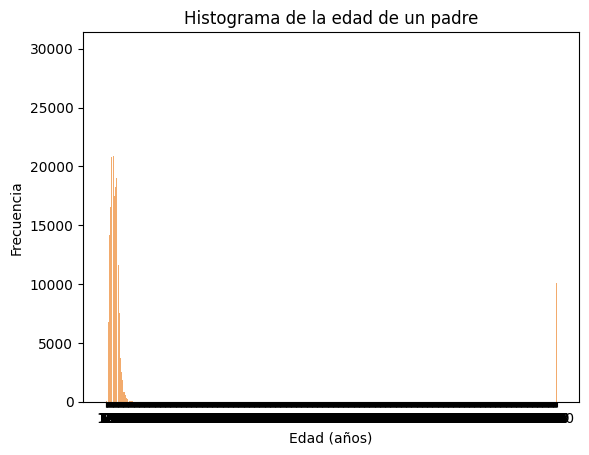

In [ ]:
import matplotlib.pyplot as plot
intervalos = range(min(df.EDAD_PADRE), max(df.EDAD_PADRE) + 2)
plot.hist(x=df.EDAD_PADRE, bins=intervalos, color='#F2AB6D', rwidth=0.85)
plot.title('Histograma de la edad de un padre')
plot.xlabel('Edad (años)')
plot.ylabel('Frecuencia')
plot.xticks(intervalos)
plot.show()

In [ ]:
df1 = df[(df.EDAD_PADRE < 120) & (df.EDAD_MADRE != 99) & (df.N_HIJOSV != 99)]
df1.head(5)

,EDAD_PADRE,EDAD_MADRE,N_HIJOSV
COD_DPTO,,,
76,39,6,2
19,27,4,3
41,28,4,3
50,27,2,1
50,31,4,5


/tmp/ipykernel_1206/2100819326.py:14: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k" (-> color=(0.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(x, p, 'k', linewidth=2, label='Distribución Normal',color="blue")


<Axes: xlabel='EDAD_PADRE', ylabel='Density'>

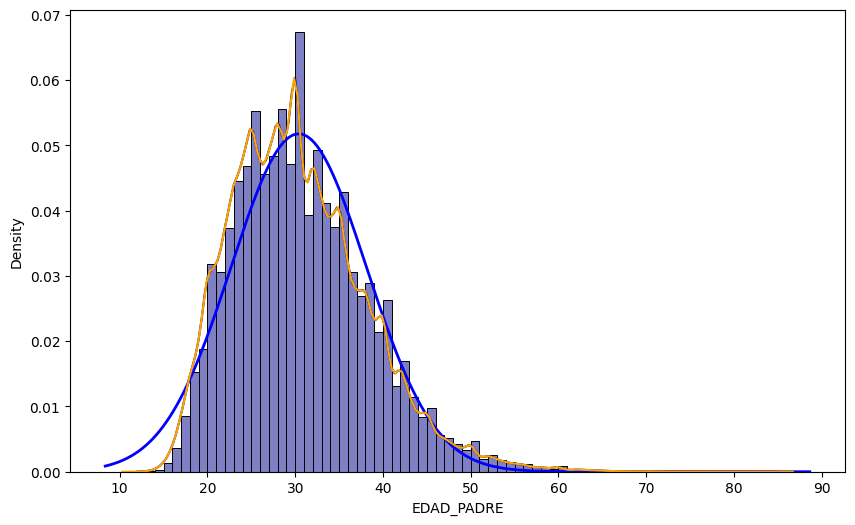

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

intervalos1=range(min(df1.EDAD_PADRE), max(df1.EDAD_PADRE)+1)
plt.figure(figsize=(10,6))
sns.histplot(x=df1.EDAD_PADRE, bins=intervalos1, kde=True, stat='density', color='darkblue', edgecolor='black')

xmin, xmax=plt.xlim()
x=np.linspace(xmin, xmax, 1000)
p=norm.pdf(x,np.mean(df1.EDAD_PADRE),np.std(df1.EDAD_PADRE))

plt.plot(x, p, 'k', linewidth=2, label='Distribución Normal',color="blue")
sns.kdeplot(x=df1.EDAD_PADRE,color="orange")

In [ ]:
#Prueba de hipotesis - shapiro
from scipy.stats import shapiro
shapiro(df1.EDAD_PADRE)

ShapiroResult(statistic=np.float64(0.9677165978499048), pvalue=np.float64(7.672928032033413e-109))

In [ ]:
df1.EDAD_PADRE.count()

np.int64(443803)